# CHATBOT CIMA — Actividad 5
## Entrenamiento supervisado, GridSearchCV y MLflow

El experimento compara **TF-IDF + Regresión Logística** y **TF-IDF + LinearSVC**. Se ajustan hiperparámetros con validación cruzada sobre entrenamiento y se evalúa una única vez con una muestra reservada. Las métricas solo existen después de ejecutar las celdas.

### 1. Instalar dependencias y configurar el entorno
Colab funciona con CPU para estos dos clasificadores; no requiere GPU. Reiniciar la sesión si Colab solicita actualizar dependencias.

In [1]:
%pip -q install "mlflow>=2.20,<4" "pandas>=2.1,<3" "scikit-learn>=1.4,<2" "matplotlib>=3.8,<4" "joblib>=1.3,<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 84.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 127.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 90.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

### 2. Cargar el paquete de trabajo
Sube el archivo **Actividad5_Entrenamiento_v1.zip** suministrado con el proyecto. La carpeta `Actividad5` contiene el CSV original versionado y los scripts reproducibles. El notebook puede guardarse posteriormente en GitHub; no requiere la base maestra operativa.

In [2]:
from google.colab import files
from pathlib import Path
import zipfile
uploads = files.upload()
archivo = next((n for n in uploads if n.endswith('.zip')), None)
assert archivo, 'Selecciona Actividad5_Entrenamiento_v1.zip'
with zipfile.ZipFile(archivo) as z:
    bad = [x for x in z.namelist() if x.startswith('/') or '..' in Path(x).parts]
    assert not bad, f'Rutas no seguras en ZIP: {bad}'
    z.extractall('/content')
ROOT = Path('/content/Actividad5')
assert (ROOT/'fuentes'/'train.py').is_file()
assert (ROOT/'fuentes'/'datos_prep.py').is_file()
print('Proyecto cargado:', ROOT)

Saving Actividad5_Entrenamiento_v1.zip to Actividad5_Entrenamiento_v1.zip
Proyecto cargado: /content/Actividad5


### 3. Preparar, versionar y visualizar los datos
El archivo original queda intacto. Se normalizan espacios y se eliminan textos duplicados solo en el dataset de entrenamiento; se genera una nueva partición sin textos idénticos compartidos.

In [3]:
!python /content/Actividad5/fuentes/datos_prep.py

Datos originales: 160  / limpios: 128
Duplicados retirados: 32
Textos repetidos entre particiones anteriores: 6
Clases limpias:
 clase_real
INDIVIDUAL       40
PAQUETE          38
AMBIGUA          10
FUERA_ALCANCE    40
Train/test:
 particion_a5   entrenamiento  prueba
clase_real                          
INDIVIDUAL                32       8
PAQUETE                   30       8
AMBIGUA                    8       2
FUERA_ALCANCE             32       8
SHA256 original: d9949a464ff67d28efca2a8c0e3e18a75c830b28e3b57376a114d48fdba43d05
SHA256 limpio: 0ee6d271d9d35d7c30fb82f0dcf4f4cbdebe3e4b0b726c87ec8e44d22e2a54e6


01_antes_despues_duplicados.png


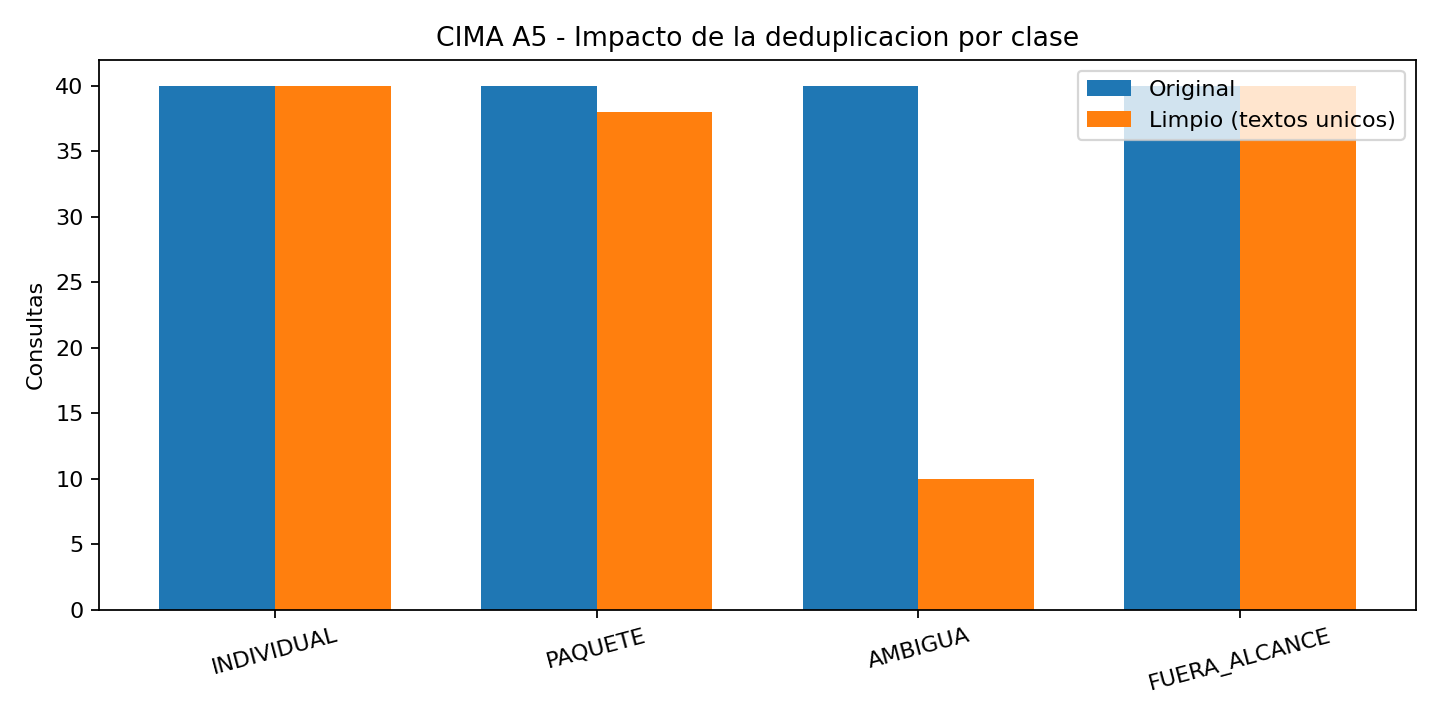

02_particiones_clases.png


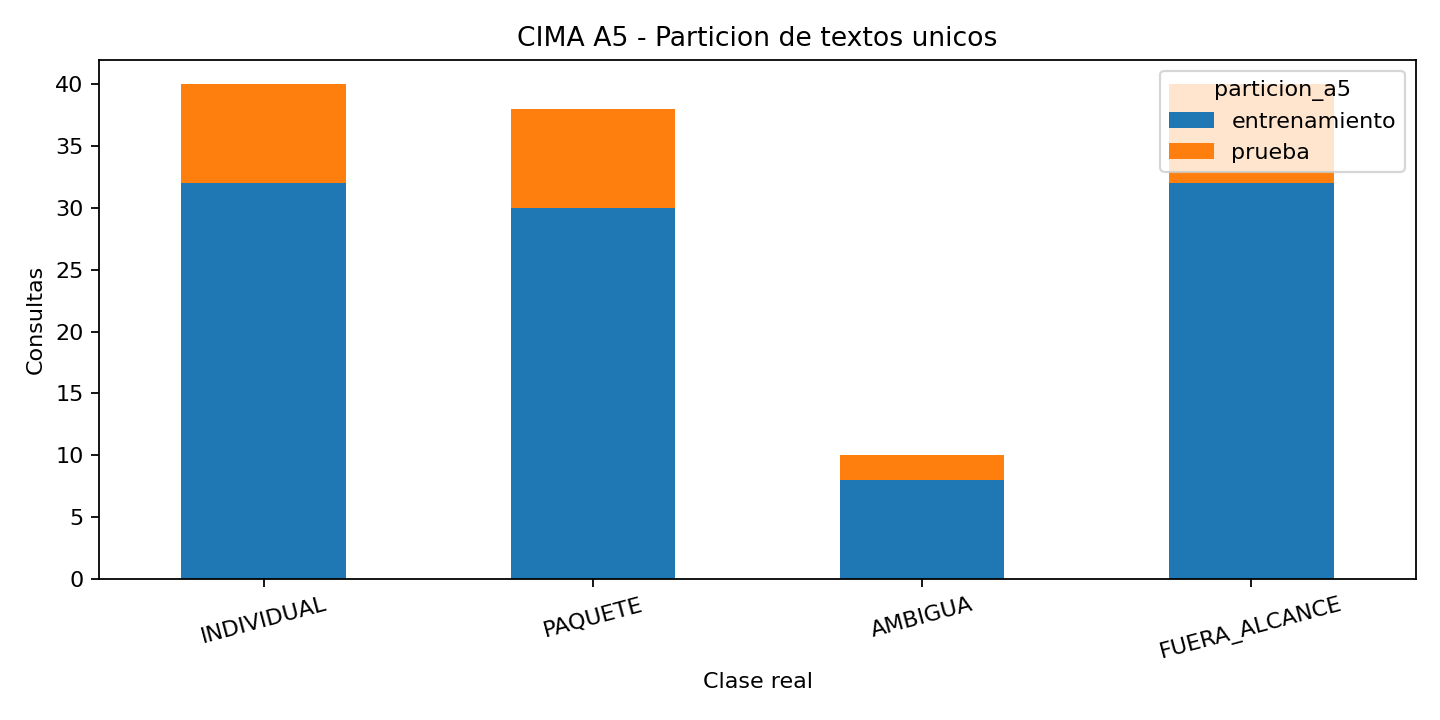

In [4]:
from IPython.display import display, Image
for f in sorted((ROOT/'resultados').glob('0*.png')):
    print(f.name)
    display(Image(filename=str(f)))

### 4. Entrenar dos modelos y registrar los experimentos con MLflow
Se ejecuta `GridSearchCV` con cuatro pliegues estratificados. TF-IDF se ajusta dentro de los pliegues, evitando fuga de información. El conjunto de prueba de 26 registros solo participa una vez al final.

In [15]:
!python /content/Actividad5/fuentes/train.py

MLflow Tracking URI: sqlite:////content/Actividad5/mlflow.db
2026/10/17 06:28:57 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/17 06:28:57 INFO mlflow.store.db.utils: Updating database tables
2026/10/17 06:28:59 INFO mlflow.tracking.fluent: Experiment with name 'CIMA_Actividad5_NLP_Supervisado' does not exist. Creating a new experiment.
Regresion_Logistica F1 macro: 1.0 falsas elegibilidades: 0
LinearSVC F1 macro: 0.902 falsas elegibilidades: 1
Archivos de resultados: /content/Actividad5/resultados/entrenamiento
Panel MLflow: mlflow ui --backend-store-uri sqlite:////content/Actividad5/mlflow.db --port 5000


### 5. Comparar resultados, matrices de confusión y configuración

,modelo,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr_macro_scores,cv_best_f1_macro,cv_best_f1_std,false_eligibility_count,prediction_latency_ms_per_text_batch
0,Regresion_Logistica,1.000000,1.000000,1.000,1.000000,1.0,0.918627,0.048695,0,0.075942
1,LinearSVC,0.961538,0.972222,0.875,0.901961,1.0,0.849214,0.091361,1,0.062931


matriz_LinearSVC.png


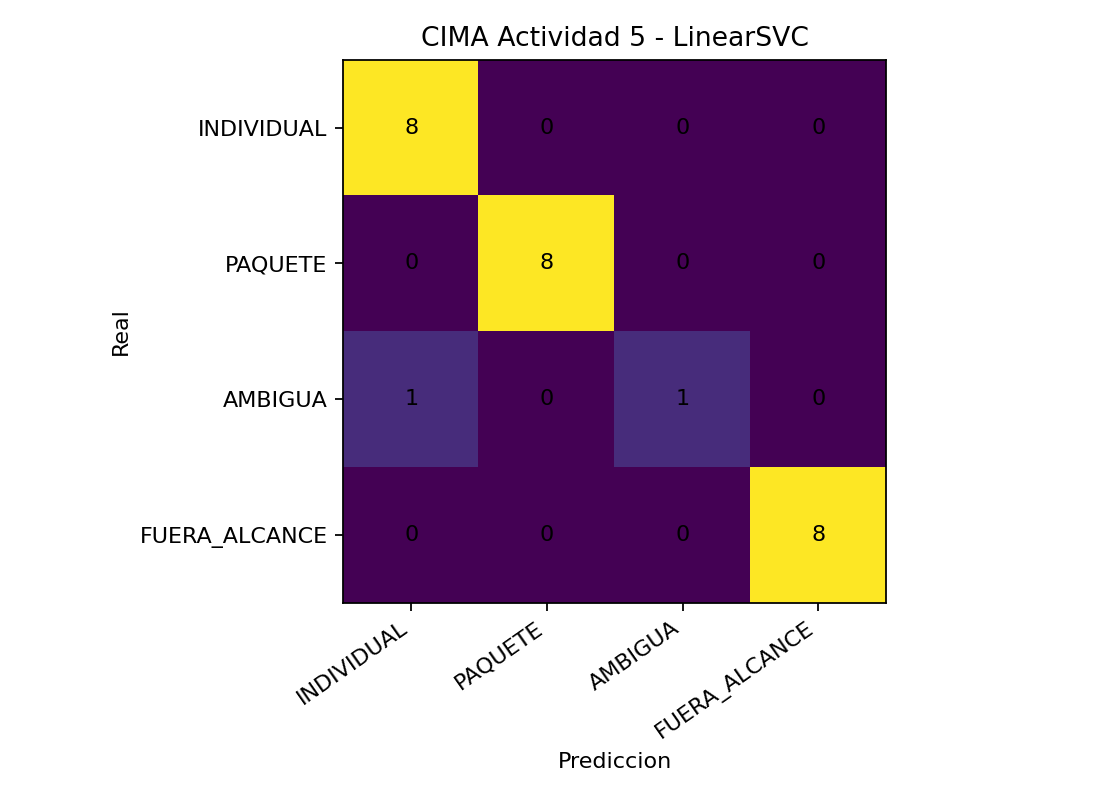

matriz_Regresion_Logistica.png


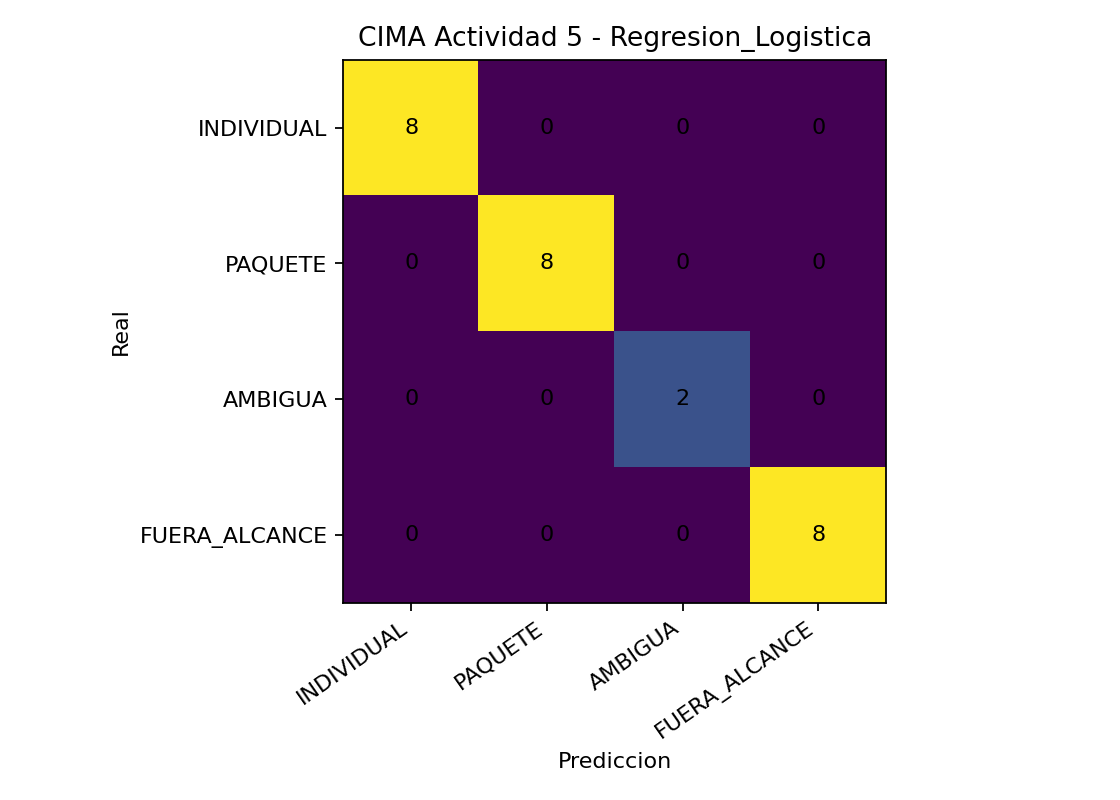

In [16]:
import pandas as pd
from IPython.display import display, Image
RESULTS = ROOT / 'resultados' / 'entrenamiento'
metrics = pd.read_csv(RESULTS/'metricas.csv')
display(metrics[['modelo','accuracy','precision_macro','recall_macro','f1_macro','roc_auc_ovr_macro_scores','cv_best_f1_macro','cv_best_f1_std','false_eligibility_count','prediction_latency_ms_per_text_batch']])
for f in sorted(RESULTS.glob('matriz_*.png')):
    print(f.name)
    display(Image(filename=str(f)))

### 6. Evidencia del registro de MLflow
La siguiente celda lee directamente el almacén local de MLflow y muestra ejecuciones, parámetros y métricas. Guarda una captura de pantalla de esta tabla como evidencia académica. También puede abrirse la interfaz gráfica MLflow en un entorno con acceso local al puerto 5000.

In [19]:

import mlflow
from pathlib import Path
from IPython.display import display

# Utilizar la misma base de datos SQLite que train.py
ROOT = Path("/content/Actividad5")
TRACKING_DB = ROOT / "mlflow.db"

assert TRACKING_DB.is_file(), (
    f"No se encontro la base de datos de MLflow: {TRACKING_DB}. "
    "Primero ejecuta correctamente el entrenamiento."
)

mlflow.set_tracking_uri(
    f"sqlite:///{TRACKING_DB.resolve().as_posix()}"
)

print("MLflow Tracking URI:", mlflow.get_tracking_uri())

experimento = mlflow.get_experiment_by_name(
    "CIMA_Actividad5_NLP_Supervisado"
)

assert experimento is not None, (
    "No se encontro el experimento en MLflow."
)

runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

assert not runs.empty, (
    "El experimento existe, pero no contiene ejecuciones registradas."
)

print(f"Experimentos registrados: {len(runs)}")

columnas = [
    "tags.mlflow.runName",
    "metrics.accuracy",
    "metrics.f1_macro",
    "metrics.cv_best_f1_macro",
    "metrics.false_eligibility_count",
    "metrics.roc_auc_ovr_macro_scores",
]

columnas_disponibles = [
    columna for columna in columnas
    if columna in runs.columns
]

display(runs[columnas_disponibles])


MLflow Tracking URI: sqlite:////content/Actividad5/mlflow.db
Experimentos registrados: 2


,tags.mlflow.runName,metrics.accuracy,metrics.f1_macro,metrics.cv_best_f1_macro,metrics.false_eligibility_count,metrics.roc_auc_ovr_macro_scores
0,LinearSVC,0.961538,0.901961,0.849214,1.0,1.0
1,Regresion_Logistica,1.000000,1.000000,0.918627,0.0,1.0


### 7. Exportar resultados y evidencia reproducible
Esta exportacion incluye las metricas, la base SQLite y copias de los artefactos de ambas ejecuciones de MLflow. Las URI originales de SQLite conservan sus rutas de Colab.


In [ ]:
# Exportar resultados y evidencia MLflow sin repetir entrenamiento
from google.colab import files
from pathlib import Path
import shutil
import mlflow

ROOT = Path('/content/Actividad5')
DEST = Path('/content/CIMA_Actividad5_resultados')
DEST.mkdir(parents=True, exist_ok=True)
shutil.copytree(ROOT / 'resultados', DEST / 'resultados', dirs_exist_ok=True)

DB = ROOT / 'mlflow.db'
assert DB.is_file(), 'No existe mlflow.db; ejecuta primero el entrenamiento.'
shutil.copy2(DB, DEST / 'mlflow.db')
mlflow.set_tracking_uri(f"sqlite:///{DB.resolve().as_posix()}")
exp = mlflow.get_experiment_by_name('CIMA_Actividad5_NLP_Supervisado')
assert exp is not None, 'No se encontro el experimento MLflow.'
runs = mlflow.search_runs(experiment_ids=[exp.experiment_id])
assert len(runs) >= 2, 'Faltan ejecuciones en MLflow.'

# Guardar copias portables de todos los artefactos por run.
for run_id in runs['run_id']:
    local_artifacts = mlflow.artifacts.download_artifacts(run_id=run_id)
    shutil.copytree(local_artifacts, DEST / 'mlflow_artifacts' / run_id, dirs_exist_ok=True)

# NOTA: el archivo SQLite conserva las URI del entorno original de Colab.
# Las copias en mlflow_artifacts permiten auditar los archivos independientemente.
zip_path = shutil.make_archive('/content/CIMA_Actividad5_resultados_completo', 'zip', DEST)
print('Ejecuciones registradas:', len(runs))
print('Base SQLite incluida:', (DEST / 'mlflow.db').is_file())
print('Copia de artefactos incluida:', (DEST / 'mlflow_artifacts').is_dir())
print('ZIP:', zip_path)
files.download(zip_path)


### 8. Interpretación y límites
**No definir un ganador antes de ejecutar.** Comparar F1 macro y su variación entre pliegues, tasa de falsa elegibilidad, tiempo y complejidad. La clase AMBIGUA tiene muy pocos ejemplos diferentes; las métricas de prueba pueden ser inestables. La validación con solicitudes sintéticas no demuestra generalización operativa. No utilizar el clasificador para confirmar pagos: esa función pertenece a la fuente autorizada, reglas verificables y supervisión humana.